# **Flu & Meteorlogical triggers**

### Local Data Dictionary:
| Variable Name | Description |
| --- | --- |
|`disease_df`|Raw infectious disease DataFrame|
|`hk_flu_df`|Flu data got from Health Burea|
|`WHO_df`|Flu data got from WHO|
|`flu_df`|All flu data|
|`weather_df`|Combined DataFrame with all the weather impacts needed|
|`cleaned_weather_df`|All weather data|
|`max_temp_df`, `min_temp_df`, `mean_temp_df`|Raw temperature DataFrames|
|`RH_df`|Raw mean humidity DataFrame|
|`df`|Final DataFrame with all weather and flu columns|

### 'df' Data Dictionary:
| Column | Description | Value |
| --- | --- | --- |
|`Year`|Year (MMWR format)|
|`Week`|Week number (MMWR format)|
|`From`|Week Start Date (MMWR format)|
|`Max temperature (°C)`|maximum temperature|
|`Min temperature (°C)`|minimum temperature|
|`Mean temperature (°C)`|minimum temperature|
|`Mean humidity (%)`|mean relative humidity|
|`Solar Radiation (MJ/m²)`|golbal solar radiation|
|`H1`||
|`H3`||
|`B`||
|`AandB`||
|`H1_proportion`|NA from 1997 to 2013, H1:number of specimen tested|
|`H3_proportion`|NA from 1997 to 2013, H3:number of specimen tested|
|`B_proportion`|NA from 1997 to 2013, B:number of specimen tested|
|`AandB_proportion`|NA from 1997 to 2013, (A+B):number of specimen tested|

### Project Variations
1. Quantifies the differences in the severity or incidence of influenza during winter peaks compared to any summer outbreaks.
2. Determine if ther's a delayed effect between specific weather conditions and a rise in flu cases.
3. 
4. 
5. International Flu Strain & Seasonal Sync Benchmarking: Compares Hong Kong's flu season patterns and dominant strains with international trends. 

### Folder tree structure:
```text
🗂️ Project-Root/
├── 📁 dataset/
│   └── 📁 daily max temp
│       └── 📄 CLMMAXT_CCH_.csv
│       └── 📄 ...
│   └── 📁 daily min temp
│       └── 📄 CLMMINT_CCH_.csv
│       └── 📄 ...
│   └── 📁 daily mean temp
│       └── 📄 CLMTEMP_CCH_.csv
│       └── 📄 ...
│   └── 📁 daily global solar radiation
│       └── 📄 daily_KSC_GSR_ALL.csv
│       └── 📄 daily_KP_GSR_ALL.csv
│   └── 📁 daily mean humidity
│       └── 📄 daily_CCH_DEW_ALL.csv
│       └── 📄 ...
│   └── 📁 daily mean dew point temperature
│       └── 📄 daily_CCH_RH_ALL.csv
│       └── 📄 ...
│   └── 📁 daily mean pressure
│       └── 📄 daily_CCH_MSLP_ALL.csv
│       └── 📄 ...
│   └── 📁 daily mean wind speed
│       └── 📄 daily_BHD_WSPD_ALL.csv
│       └── 📄 ...
│   └── 📁 daily total rainfall
│       └── 📄 daily_CCH_RF_ALL.csv
│       └── 📄 ...
│   └── 📁 flu_data_hk
│       └── 📄 flu_data.csv
│       └── 📄 flu_data_v2.csv
│       └── 📄 flux_spec_en.pdf
│       └── 📄 flux_spec_tc.pdf
│   └── 📁 WHO_data
│       └── 📄 WHO_data.csv
│       └── 📄 WHO_data_v2.csv
│       └── 📄 WHO_spec_en.csv
│   └── 📁 IVRS_data
│       └── 📄 2014.csv
│       └── 📄 ...
├── 📄 data.csv
├── 📄 flu_data.csv
├── 📄 weather_data.csv
├── 📓 cleaning.ipynb
└── 📓 presentation.ipynb

```



### Problem from dataset:
- 1990/02/19 exists in weather dataframe -> unable to convert data type to datetime (solved by dropping the related rows before doing data type conversion)
- weather statistics gained from the Hong Kong Observatory station cannot gain location (solved by manually coorect the format in the csv file)
- NA values in year, date, day (solved by dropping the related rows)
- missing rows from WHO dataset
  => 
- For HK flu data, in 2023 week 16, the number of detections of A and B is not consistent with the other columns (where A and B is 1 case less than the total)
  -> solved (checked the flue express document, and it indicate the correct value instead of the wrong value)
- AandB is H1+H3+B or A+B
inconsistent between flu express publication and the dataset we found

---

In [34]:
%pip install pandas
%pip install numpy
%pip install epiweeks
%pip install matplotlib
%pip install seaborn
%pip install plotly

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [35]:
# Import neccessary libraries
import os
import re 
import glob
from epiweeks import Week
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px

In [36]:
# Display setting
pd.options.display.max_rows = 5
pd.options.display.max_columns = 25


## **Data Preparation**

### Read csv files

#### data from WHO and data from HK

In [37]:
path = os.getcwd()
path += "\\dataset\\WHO_data\\WHO_v2.csv"
WHO_df = pd.read_csv(path)
print("WHO_df: ")
display(WHO_df)
WHO_df.columns = ["Year", "Week", "From", "H1", "H3", "B", "AandB"]

path = os.getcwd()
path += "\\dataset\\flu_data_hk\\flux_data_v2.csv"
hk_flu_df = pd.read_csv(path)
print("\nhk_flu_df: ")
display(hk_flu_df)

WHO_df: 


,YEAR,WEEK,FROM,H1,H3,B,AandB
0,1997,1,12/29/1996,NaN,1.0,5.0,6.0
1,1997,2,1/5/1997,NaN,1.0,1.0,2.0
...,...,...,...,...,...,...,...
773,2013,52,12/22/2013,0.0,73.0,40.0,159.0
774,2014,1,12/29/2013,0.0,111.0,66.0,271.0



hk_flu_df: 


,Year,Week,From,H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
0,2014,1,29/12/2013,93,111,64,268,0.0430,0.0513,0.0296,0.1238
1,2014,2,5/1/2014,230,140,109,479,0.0954,0.0580,0.0452,0.1986
...,...,...,...,...,...,...,...,...,...,...,...
661,2026,36,30/08/2026,1088,181,55,1367,0.1038,0.0173,0.0052,0.1305
662,2026,37,6/9/2026,1091,120,64,1301,0.1062,0.0117,0.0062,0.1266


In [38]:
# Function for reading weather datas
def read_file():
    # Create an empty list for storing the DataFrames
    df_list = []

    # Read all the files and process it 
    for f in csv_files:
        # Retrieve the second row to get the location (station) English name
        temp_df = pd.read_csv(f, skiprows=1, header=None, nrows=1, usecols=[0], names=["raw_line"])
        location = temp_df["raw_line"].str.split("- ")[0][1] # manually corrected the second line in the dataset for HKO
        ''' 
        if "(" in location:
            location = location.split(" (")[0]
        '''
        # Read the remaining file and add a new column 'Location' to it 
        temp_df = pd.read_csv(f, skiprows=2, skipfooter=3, engine="python")
        temp_df["Location"] = location
        # Append the DataFrae into the list 
        df_list.append(temp_df)

    # Concat all the DataFrames into one 
    df = pd.concat(df_list, ignore_index=True)
    return df
    

#### Daily maximum, minimum, mean temperature

In [39]:
# Locate where the datasets are stored
path = os.getcwd()
path += "\\dataset\\daily max temp"
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Get the DataFrame with the pre-defined function
max_temp_df = read_file()
max_temp_df

# data.to_csv("", index=False, encoding="utf-8-sig")

,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness,Location
0,1992,4,1,21.1,#,Cheung Chau
1,1992,4,2,20.3,#,Cheung Chau
...,...,...,...,...,...,...
381443,2026,7,30,32.1,C,Yuen Long Park
381444,2026,7,31,26.5,C,Yuen Long Park


In [40]:
# Locate where the datasets are stored
path = os.getcwd()
path += "\\dataset\\daily min temp"
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Get the DataFrame with the pre-defined function
min_temp_df = read_file()
min_temp_df

# data.to_csv("", index=False, encoding="utf-8-sig")

,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness,Location
0,1992,4,1,18.7,#,Cheung Chau
1,1992,4,2,17.4,#,Cheung Chau
...,...,...,...,...,...,...
381443,2026,7,30,24.3,C,Yuen Long Park
381444,2026,7,31,23.9,C,Yuen Long Park


In [41]:
# Locate where the datasets are stored
path = os.getcwd()
path += "\\dataset\\daily mean temp"
csv_files = glob.glob(os.path.join(path, "*.csv"))

# Get the DataFrame with the pre-defined function
mean_temp_df = read_file()
mean_temp_df

# data.to_csv("", index=False, encoding="utf-8-sig")

,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness,Location
0,1992,4,1,19.3,#,Cheung Chau
1,1992,4,2,18.5,#,Cheung Chau
...,...,...,...,...,...,...
382769,2026,8,30,NaN,NaN,Yuen Long Park
382770,2026,8,31,NaN,NaN,Yuen Long Park


#### Daily mean relative humidity

In [42]:
# Locate where the datasets are stored
path = os.getcwd()
path += "\\dataset\\daily mean humidity"
csv_files = glob.glob(os.path.join(path, "*.csv"))

RH_df = read_file()
RH_df
# data.to_csv("", index=False, encoding="utf-8-sig")


,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness,Location
0,1992.0,4.0,1.0,97,#,Cheung Chau
1,1992.0,4.0,2.0,95,#,Cheung Chau
...,...,...,...,...,...,...
262491,2026.0,8.0,30.0,NaN,NaN,Tai Po(Yuen Chau Tsai Park)
262492,2026.0,8.0,31.0,NaN,NaN,Tai Po(Yuen Chau Tsai Park)


#### Daily global solar radiation

In [43]:
# Locate where the datasets are stored
path = os.getcwd()
path += "\\dataset\\daily global solar radiation"
csv_files = glob.glob(os.path.join(path, "*.csv"))

SR_df = read_file()
SR_df
# data.to_csv("", index=False, encoding="utf-8-sig")

,年/Year,月/Month,日/Day,數值/Value,數據完整性/data Completeness,Location
0,1978,11,1,***,NaN,King's Park
1,1978,11,2,***,NaN,King's Park
...,...,...,...,...,...,...
24074,2026,8,30,8.18,C,Kau Sai Chau
24075,2026,8,31,11.13,C,Kau Sai Chau


### Cleaning

#### Data type conversion for flu data and DataFrame concatenation

In [44]:
# for the column 'From' to datetime
hk_flu_df["From"] = pd.to_datetime(hk_flu_df["From"], format="%d/%m/%Y")
WHO_df["From"] = pd.to_datetime(WHO_df["From"], format="%m/%d/%Y")

# concatenate the two DataFrames
flu_df = pd.concat([hk_flu_df, WHO_df], ignore_index=True)

# Sort it by the date
flu_df = flu_df.sort_values(["Year", "Week"])

# flu_df["From"] = pd.to_datetime(flu_df["From"])
flu_df["From"] = pd.to_datetime([Week(y, w, validate=False).startdate() for y, w in zip(flu_df["Year"], flu_df["Week"])])

# Display results
print("flu_df: ")
with pd.option_context("display.max_rows", 20):
    display(flu_df)

flu_df: 


,Year,Week,From,H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
663,1997,1,1996-12-29,NaN,1.0,5.0,6.0,NaN,NaN,NaN,NaN
664,1997,2,1997-01-05,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN
665,1997,3,1997-01-12,NaN,5.0,6.0,11.0,NaN,NaN,NaN,NaN
666,1997,4,1997-01-19,NaN,2.0,9.0,11.0,NaN,NaN,NaN,NaN
667,1997,5,1997-01-26,NaN,1.0,21.0,22.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
658,2026,33,2026-08-16,713.0,356.0,89.0,1190.0,0.0619,0.0309,0.0077,0.1033
659,2026,34,2026-08-23,735.0,245.0,65.0,1077.0,0.0702,0.0234,0.0062,0.1029
660,2026,35,2026-08-30,846.0,206.0,60.0,1148.0,0.0823,0.0200,0.0058,0.1117
661,2026,36,2026-09-06,1088.0,181.0,55.0,1367.0,0.1038,0.0173,0.0052,0.1305


#### Rename the columns for all weather DataFrames

In [45]:
max_temp_df.columns = ["Year", "Month", "Day", "Max temperature", "data Completeness", "Location"]
min_temp_df.columns = ["Year", "Month", "Day", "Min temperature", "data Completeness", "Location"]
mean_temp_df.columns = ["Year", "Month", "Day", "Mean temperature", "data Completeness", "Location"]
RH_df.columns = ["Year", "Month", "Day", "Mean humidity", "data Completeness", "Location"]
SR_df.columns = ["Year", "Month", "Day", "Solar radiation", "data Completeness", "Location"]

#### Data type conversion for all the weather DataFrames

In [46]:
# Function for data type conversion
def data_type_conversion(df_name):
    df_name["Year"] = df_name["Year"].astype(int)
    df_name["Month"] = df_name["Month"].astype(int)
    df_name["Day"] = df_name["Day"].astype(int)
    df_name["Date"] = df_name["Year"].astype(str) + "/" + df_name["Month"].astype(str) + "/" + df_name["Day"].astype(str)
    df_name.drop(["Year", "Month", "Day"], axis=1, inplace=True)
    
    drop_index = df_name[df_name["Date"] == "1900/2/29"].index
    df_name.drop(drop_index, inplace=True)
    df_name["Date"] = pd.to_datetime(df_name["Date"], format="mixed")
    

In [47]:
# Apply the function to the DataFrames
data_type_conversion(max_temp_df)
data_type_conversion(min_temp_df)
data_type_conversion(mean_temp_df)
data_type_conversion(SR_df)

drop_index = RH_df[RH_df["Month"].isna()].index
RH_df.drop(drop_index, inplace=True)

data_type_conversion(RH_df)

#### FIlter out date that are not needed

In [48]:
# Function for filtering the rows for the date
max_date = min(max(max_temp_df["Date"]), max(min_temp_df["Date"]), max(mean_temp_df["Date"]), max(RH_df["Date"]), max(SR_df["Date"]))
def drop_rows(df_name):
    drop_index = df_name[df_name["Date"] > max_date].index
    df_name.drop(drop_index, inplace=True)


In [49]:
# Apply the function to the DataFrames
drop_rows(max_temp_df)
drop_rows(min_temp_df)
drop_rows(mean_temp_df)
drop_rows(RH_df)
drop_rows(SR_df)

#### Drop all the rows with null value from weather DataFrames

In [50]:
# find all the index of rows that need to be deleted
drop_index = max_temp_df[max_temp_df["Max temperature"] == "***"].index.to_list()
drop_index += min_temp_df[min_temp_df["Min temperature"] == "***"].index.to_list()
drop_index += mean_temp_df[mean_temp_df["Mean temperature"] == "***"].index.to_list()
drop_index += RH_df[RH_df["Mean humidity"] == "***"].index.to_list()
drop_index += SR_df[SR_df["Solar radiation"] == "***"].index.to_list()
drop_index = set(drop_index)

# drop the rows in all weather DataFrames
max_temp_df.drop(drop_index, inplace=True)
min_temp_df.drop(drop_index, inplace=True)
mean_temp_df.drop(drop_index, inplace=True)
RH_df.drop(drop_index, inplace=True, errors="ignore")
SR_df.drop(drop_index, inplace=True, errors="ignore")


#### Combine all the weather DataFrames

In [51]:
weather_df = max_temp_df.drop("data Completeness", axis=1).merge(min_temp_df.drop("data Completeness", axis=1), how="right", on=["Date", "Location"], validate="many_to_one")
weather_df = weather_df.merge(mean_temp_df.drop("data Completeness", axis=1), how="right", on=["Date", "Location"], validate="many_to_one")
weather_df = weather_df.merge(RH_df.drop("data Completeness", axis=1), how="left", on=["Date", "Location"], validate="many_to_one")
weather_df = weather_df.merge(SR_df.drop("data Completeness", axis=1), how="left", on=["Date", "Location"])
weather_df = weather_df.reindex(["Date", "Location", "Max temperature", "Min temperature", "Mean temperature", "Mean humidity", "Solar radiation"], axis=1)

display(weather_df)
weather_df.info()


,Date,Location,Max temperature,Min temperature,Mean temperature,Mean humidity,Solar radiation
0,1992-05-01,Cheung Chau,30.4,24.4,26.6,89,NaN
1,1992-05-02,Cheung Chau,29.6,24.3,26.2,90,NaN
...,...,...,...,...,...,...,...
367102,2026-08-30,Yuen Long Park,NaN,NaN,NaN,NaN,NaN
367103,2026-08-31,Yuen Long Park,NaN,NaN,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367104 entries, 0 to 367103
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Date              367104 non-null  datetime64[ns]
 1   Location          367104 non-null  object        
 2   Max temperature   358753 non-null  object        
 3   Min temperature   358753 non-null  object        
 4   Mean temperature  366092 non-null  object        
 5   Mean humidity     230043 non-null  object        
 6   Solar radiation   18207 non-null   object        
dtypes: datetime64[ns](1), object(6)
memory usage: 19.6+ MB


In [52]:
# Drop rows with null values
drop_index = weather_df.index[weather_df.drop(["Date", "Location"], axis=1).isnull().all(1)]
weather_df.drop(drop_index, inplace=True)

In [53]:
weather_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 366152 entries, 0 to 367072
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Date              366152 non-null  datetime64[ns]
 1   Location          366152 non-null  object        
 2   Max temperature   358753 non-null  object        
 3   Min temperature   358753 non-null  object        
 4   Mean temperature  366092 non-null  object        
 5   Mean humidity     230043 non-null  object        
 6   Solar radiation   18207 non-null   object        
dtypes: datetime64[ns](1), object(6)
memory usage: 22.3+ MB


In [54]:
# change datatype to float of the numeric columns
weather_df[["Max temperature", "Min temperature", "Mean temperature", "Mean humidity", "Solar radiation"]] = weather_df[["Max temperature", "Min temperature", "Mean temperature", "Mean humidity", "Solar radiation"]].astype(float)

weather_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 366152 entries, 0 to 367072
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Date              366152 non-null  datetime64[ns]
 1   Location          366152 non-null  object        
 2   Max temperature   358753 non-null  float64       
 3   Min temperature   358753 non-null  float64       
 4   Mean temperature  366092 non-null  float64       
 5   Mean humidity     230043 non-null  float64       
 6   Solar radiation   18207 non-null   float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 22.3+ MB


In [55]:
# group the rows according to the date
cleaned_weather_df = weather_df.drop(["Location"], axis=1).groupby(pd.Grouper(key="Date", axis=0, freq="W-SUN", closed="left", label="left")).mean().round(2)
display(cleaned_weather_df)


,Max temperature,Min temperature,Mean temperature,Mean humidity,Solar radiation
Date,,,,,
1884-03-30,17.83,15.20,16.38,NaN,NaN
1884-04-06,21.47,17.07,19.14,NaN,NaN
...,...,...,...,...,...
2026-08-23,31.51,27.84,29.56,82.14,14.24
2026-08-30,29.80,27.15,28.40,84.50,9.05


In [56]:
# Add the columns 'Year', 'Week', and 'From'
cleaned_weather_df["Year"] = pd.Series(cleaned_weather_df.index, index=cleaned_weather_df.index).apply(lambda d: Week.fromdate(d).year)
cleaned_weather_df["Week"] = pd.Series(cleaned_weather_df.index, index=cleaned_weather_df.index).apply(lambda d: Week.fromdate(d).week)
cleaned_weather_df["From"] = cleaned_weather_df.index

cleaned_weather_df["Diurnal temperature range"] = cleaned_weather_df["Max temperature"] - cleaned_weather_df["Min temperature"]

# Re-index
cleaned_weather_df.index = pd.RangeIndex(0, cleaned_weather_df.shape[0])
cleaned_weather_df = cleaned_weather_df.reindex(["Year", "Week", "From", "Diurnal temperature range", "Mean temperature", "Mean humidity", "Solar radiation"], axis=1)
cleaned_weather_df.columns = ["Year", "Week", "From", "Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)"]

# Filter the DataFrame by date
cleaned_weather_df = cleaned_weather_df[cleaned_weather_df["From"] > pd.to_datetime("1996-12-28")]

display(cleaned_weather_df)
cleaned_weather_df.info()

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²)
5883,1997,1,1996-12-29,6.07,17.47,81.65,8.43
5884,1997,2,1997-01-05,7.50,12.84,61.90,13.75
...,...,...,...,...,...,...,...
7430,2026,34,2026-08-23,3.67,29.56,82.14,14.24
7431,2026,35,2026-08-30,2.65,28.40,84.50,9.05


<class 'pandas.core.frame.DataFrame'>
Index: 1549 entries, 5883 to 7431
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Year                            1549 non-null   int64         
 1   Week                            1549 non-null   int64         
 2   From                            1549 non-null   datetime64[ns]
 3   Diurnal temperature range (°C)  1549 non-null   float64       
 4   Mean temperature (°C)           1549 non-null   float64       
 5   Mean humidity (%)               1549 non-null   float64       
 6   Solar radiation (MJ/m²)         1539 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2)
memory usage: 96.8 KB


#### Final DataFrames and file output

In [57]:
print("Final DataFrames: \n\n")

print("cleaned_weather_df: ")
display(cleaned_weather_df)
cleaned_weather_df.info()
cleaned_weather_df.to_csv("weather_data.csv", index=False, encoding="utf-8-sig")

print("\nflu_df: ")
display(flu_df)
flu_df.info()
flu_df.to_csv("flu_data.csv", index=False, encoding="utf-8-sig")

Final DataFrames: 


cleaned_weather_df: 


,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²)
5883,1997,1,1996-12-29,6.07,17.47,81.65,8.43
5884,1997,2,1997-01-05,7.50,12.84,61.90,13.75
...,...,...,...,...,...,...,...
7430,2026,34,2026-08-23,3.67,29.56,82.14,14.24
7431,2026,35,2026-08-30,2.65,28.40,84.50,9.05


<class 'pandas.core.frame.DataFrame'>
Index: 1549 entries, 5883 to 7431
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Year                            1549 non-null   int64         
 1   Week                            1549 non-null   int64         
 2   From                            1549 non-null   datetime64[ns]
 3   Diurnal temperature range (°C)  1549 non-null   float64       
 4   Mean temperature (°C)           1549 non-null   float64       
 5   Mean humidity (%)               1549 non-null   float64       
 6   Solar radiation (MJ/m²)         1539 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2)
memory usage: 96.8 KB

flu_df: 


,Year,Week,From,H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
663,1997,1,1996-12-29,NaN,1.0,5.0,6.0,NaN,NaN,NaN,NaN
664,1997,2,1997-01-05,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
661,2026,36,2026-09-06,1088.0,181.0,55.0,1367.0,0.1038,0.0173,0.0052,0.1305
662,2026,37,2026-09-13,1091.0,120.0,64.0,1301.0,0.1062,0.0117,0.0062,0.1266


<class 'pandas.core.frame.DataFrame'>
Index: 1438 entries, 663 to 662
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Year              1438 non-null   int64         
 1   Week              1438 non-null   int64         
 2   From              1438 non-null   datetime64[ns]
 3   H1                1380 non-null   float64       
 4   H3                1405 non-null   float64       
 5   B                 1397 non-null   float64       
 6   AandB             1413 non-null   float64       
 7   H1_proportion     663 non-null    float64       
 8   H3_proportion     663 non-null    float64       
 9   B_proportion      663 non-null    float64       
 10  AandB_proportion  663 non-null    float64       
dtypes: datetime64[ns](1), float64(8), int64(2)
memory usage: 134.8 KB


In [58]:
# to-do
cleaned_weather_df[~cleaned_weather_df["From"].isin(flu_df["From"])]

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²)
5927,1997,45,1997-11-02,7.87,20.39,59.17,16.66
5928,1997,46,1997-11-09,7.23,23.12,76.64,14.60
...,...,...,...,...,...,...,...
7135,2020,53,2020-12-27,9.46,15.12,56.81,17.27
7396,2025,53,2025-12-28,7.55,16.20,72.67,14.35


In [59]:
df = cleaned_weather_df.merge(flu_df, how="left", on=["Year", "Week", "From"])
display(df)
df.to_csv("data.csv", index=False, encoding="utf-8-sig")

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
0,1997,1,1996-12-29,6.07,17.47,81.65,8.43,NaN,1.0,5.0,6.0,NaN,NaN,NaN,NaN
1,1997,2,1997-01-05,7.50,12.84,61.90,13.75,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2026,34,2026-08-23,3.67,29.56,82.14,14.24,735.0,245.0,65.0,1077.0,0.0702,0.0234,0.0062,0.1029
1549,2026,35,2026-08-30,2.65,28.40,84.50,9.05,846.0,206.0,60.0,1148.0,0.0823,0.0200,0.0058,0.1117


In [60]:
with pd.option_context("display.max_rows", 8):
    display(df.drop(["Year", "Week", "From"], axis=1).describe())

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
count,1550.00000,1550.000000,1550.000000,1540.000000,1375.000000,1400.000000,1392.000000,1408.000000,659.000000,659.000000,659.000000,659.000000
mean,5.70751,22.748271,79.924439,13.678591,63.574545,104.782143,41.114943,235.136364,0.018379,0.030436,0.012694,0.061970
std,1.20611,4.906529,8.581515,4.596148,179.228587,222.235183,125.304849,419.248781,0.034592,0.053787,0.028280,0.073643
min,2.65000,9.020000,39.170000,2.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.86000,18.672500,75.542500,10.450000,0.000000,4.000000,3.000000,22.000000,0.000600,0.001800,0.000700,0.007600
50%,5.63500,23.680000,81.795000,13.620000,3.000000,25.000000,11.000000,82.000000,0.004300,0.008900,0.003200,0.035100
75%,6.46000,27.170000,85.920000,16.792500,41.500000,106.250000,36.000000,254.250000,0.016950,0.037000,0.010700,0.087850
max,9.96000,31.060000,94.940000,26.570000,1999.000000,2560.000000,1978.000000,4679.000000,0.259400,0.379100,0.222300,0.405900


---

#### ** **

In [61]:
# SARS
sars_df = df[((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23"))]
display(sars_df)

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
321,2003,9,2003-02-23,6.16,20.05,85.38,12.70,0.0,87.0,44.0,135.0,NaN,NaN,NaN,NaN
322,2003,10,2003-03-02,5.71,17.09,84.42,7.65,2.0,111.0,44.0,163.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337,2003,25,2003-06-15,5.24,26.20,87.16,11.99,0.0,11.0,3.0,22.0,NaN,NaN,NaN,NaN
338,2003,26,2003-06-22,4.76,27.59,86.01,12.76,0.0,24.0,1.0,30.0,NaN,NaN,NaN,NaN


In [62]:
# COVID19
covid_df = df[((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01"))]
display(covid_df)

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
1205,2020,5,2020-01-26,7.18,13.22,63.09,14.01,846.0,116.0,41.0,1003.0,0.1196,0.0164,0.0058,0.1417
1206,2020,6,2020-02-02,3.98,16.74,80.97,7.24,266.0,33.0,21.0,320.0,0.0471,0.0058,0.0037,0.0566
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1365,2023,8,2023-02-19,7.66,17.88,67.33,19.39,7.0,19.0,6.0,32.0,0.0014,0.0037,0.0012,0.0063
1366,2023,9,2023-02-26,8.22,17.21,66.99,20.51,19.0,14.0,1.0,34.0,0.0042,0.0031,0.0002,0.0075


In [63]:
tdf = df[~(((df["From"] > "2003-02-21") & (df["From"] < "2003-06-23")) | ((df["From"] > "2020-01-23") & (df["From"] < "2023-03-01")) | (df["From"] < "2004-01-01"))]
tdf

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),H1,H3,B,AandB,H1_proportion,H3_proportion,B_proportion,AandB_proportion
366,2004,1,2004-01-04,5.68,17.94,79.08,11.50,0.0,4.0,5.0,14.0,NaN,NaN,NaN,NaN
367,2004,2,2004-01-11,6.85,15.24,73.36,10.86,0.0,9.0,0.0,13.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1548,2026,34,2026-08-23,3.67,29.56,82.14,14.24,735.0,245.0,65.0,1077.0,0.0702,0.0234,0.0062,0.1029
1549,2026,35,2026-08-30,2.65,28.40,84.50,9.05,846.0,206.0,60.0,1148.0,0.0823,0.0200,0.0058,0.1117


NameError: name 'ax2' is not defined

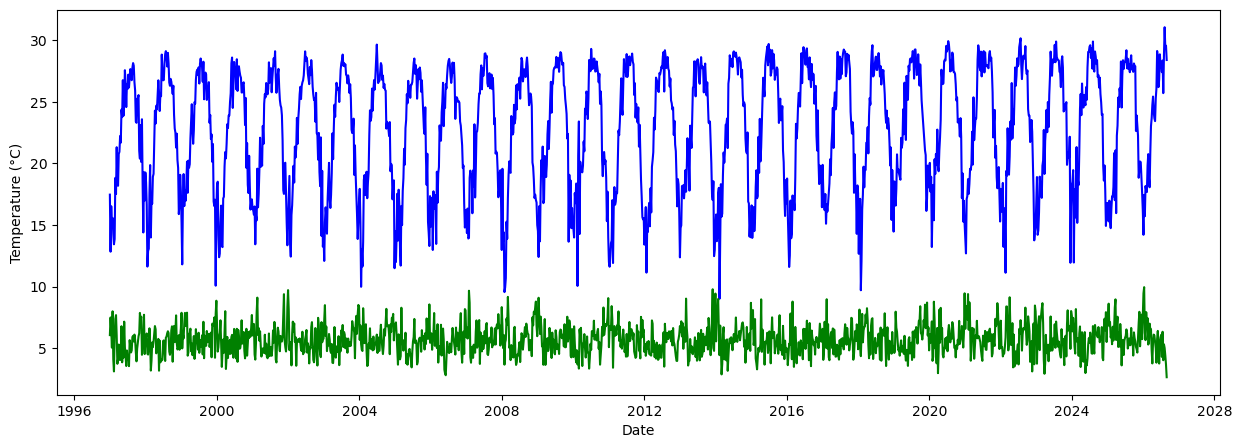

In [64]:
# to-do
fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(df["From"], df["Mean temperature (°C)"], color="blue")
ax1.plot(df["From"], df["Diurnal temperature range (°C)"], color="green")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

line2 = ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.plot(df["From"], df["Mean humidity (%)"], color="red")
ax2.set_ylabel("Mean humidity (%)")

ax1.grid(color="gray")
'''
legend_elements = [
    Line2D(), 
    Line2D()
]
ax1.legend(handle=legend_elements)
'''

plt.title("Temperatures and humidity")
plt.tight_layout()
plt.show()

In [ ]:
# correlation between meteorlogical factors and influenza detections
with pd.option_context("display.max_rows", 8):
    corr_tdf = tdf[["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "H1", "H3", "B", "AandB"]].corr()
    corr_tdf = corr_tdf.loc[["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)"], ["H1", "H3", "B", "AandB"]]
    display(corr_tdf)
sns.heatmap(corr_tdf, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.show()

In [ ]:
df_long = tdf.melt(
    id_vars=["Year"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

plt.figure(figsize=(20, 5))
sns.boxplot(df_long, x="Year", y="Influenza detections", hue="Type", palette=["red", "green", "blue"])

plt.title("")
plt.xlabel("Year")
plt.ylabel("Influenza detections")
plt.grid()
plt.show()

In [ ]:
df_long = tdf.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
for year in sorted(tdf["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.2, annotation_text="Summer", annotation_position="top left")
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.2, annotation_text="Winter", annotation_position="top left")

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.2, annotation_text="Winter", annotation_position="top left")
    
fig.show()

In [ ]:
# graph of influenza based on timeline
fig, ax = plt.subplots(figsize=(85, 15))

ax.plot(tdf["From"], tdf["H1"], color="red")
ax.plot(tdf["From"], tdf["H3"], color="green")
ax.plot(tdf["From"], tdf["B"], color="blue")
ax.grid()

ax.set_title("Number of detections")
ax.set_xlabel("Year")
ax.set_ylabel("Number of detections")
ax.legend(["AH1", "AH3", "B"])


for year in sorted(tdf["Year"].unique()): 
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    ax.axvspan(start, end, color="#ffd1dc")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Summer", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    ax.axvspan(start, end, color="#ADD8E6")

    mid_pt = start + (end - start) / 2
    ax.text(mid_pt, 2000, "Winter", horizontalalignment="center", verticalalignment="center", rotation=90, va="bottom", color="dimgray")

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)
    ax.axvspan(start, end, color="#ADD8E6")

plt.show()

In [ ]:
tdf = df.drop(["Year", "From"], axis=1).groupby("Week").mean()
tdf["Week"] = tdf.index
df_long = tdf.melt(
    id_vars=["Week"],
    value_vars=["H1", "H3", "B", "AandB"],
    var_name="Type",  
    value_name="Number of influenza detections", 
)

fig = px.line(df_long, "Week", "Number of influenza detections", color="Type", 
              title="Number of detections across every year", 
              width=1000, height=500
             )
fig.show()

#### **Influenza outbreaks during winter and summer respectively**

In [ ]:
summer_df = df[((df["Week"] >= 22) & (df["Week"] <= 35))]
winter_df = df[(((df["Week"] >= 1) & (df["Week"] <= 8)) | ((df["Week"] >= 48) & (df["Week"] <= 53)))]

display(summer_df)
display(winter_df)

---

In [65]:
AP_df

NameError: name 'AP_df' is not defined